# 프로모션·업데이트 효과 분석
어뷰저 분석 결과에 따라 **의심 계정 제외** (02_abuser_analysis.ipynb 참고)


### 분석 목표
- **프로모션 효과 분석**
  - 프로모션 기간에 신규, 기존, 복귀 유저의 증감 수 확인
  - 프로모션 기간의 유저 수가 평시 대비 유의하게 증가했는지 검정
  - 프로모션 간 평시 대비 차이가 통계적으로 유의한지 검정
- **업데이트 효과 분석**
  - 복귀 지원 프로모션 기간과 종료 후 기존 유저 수 변화를 보고 핫픽스 효과 추정
- **01_EDA.ipynb 파일에서 분석한 내용은 이 파일에서는 제외합니다.**


### 데이터 개요
- **데이터 배경**: 가상 MMORPG **Astrasia Online** 서비스 데이터

- **데이터 기간**: 2026-07-01 ~ 2026-09-28 (90일)

- **분석 대상 테이블**
  - `users.csv`: 유저 정보
  - `daily_activity.csv`: 일별 접속, 플레이타임, 골드, 아이템
  - `funnel_events.csv`: 성장 퍼널 이벤트
  - `payments.csv`: 결제 내역
- **분석 대상 유저 수**: 데이터 기간 중 **1일 이상 접속** 유저 18,401명 중 어뷰저 의심 계정 427명(2.32%)을 제외한 17,974명


### 유저 유형 정의
| 유형 | 정의 |
|---|---|
| 신규 | 가입일(D0)부터 D14까지 해당 유저 |
| 복귀 | 30일 이상 미접속 후 재접속한 날부터 14일까지 |
| 기존 | 신규, 복귀가 아닌 유저 |

- **신규 유저 기준(D14)**: EDA에서 가입 후 리텐션은 D1 38.6% → D14 9.8%로 크게 떨어진 뒤, D30까지는 3.8%p만 감소하며 완만해짐.  
  D14 이후까지 남은 유저는 비교적 꾸준히 재방문한다고 판단해, 그 전까지를 신규 유저로 적용.  
  가입 당일만 신규로 보면 신규 유저층이 너무 작아져, 프로모션 효과 분석에서는 가입 후 방문 기간을 기준으로 신규 유저를 판단.

- **복귀 유저 기준(30일)**: 업계에서 많이 쓰는 기준을 적용.  
  데이터 기간이 90일로 짧아, 기준을 길게 잡으면 복귀 유저로 분류되는 유저가 줄어 복귀 유저 분석이 어려워지기 때문에, 복귀 유저로 판단하기 적절한 기간으로 설정.

- **한계점**: 데이터 시작 일자가 7월 1일부터이기 때문에 복귀 유저는 7월 31일 이후만 구분할 수 있음.  
  이에 따라 여름 축제 1부(7/21~7/27)는 복귀 유저의 판단이 불가해, 신규 vs 기존·복귀 두 그룹으로 비교함.


### 용어 설명
- 유저는 `user_id` 단위이며, 한 사람이 여러 계정을 가지더라도 `user_id`당 한 명의 유저로 간주함.


### 목차
1. 환경설정 및 데이터 확인
2. 프로모션 효과 분석 - 유저 유형 변화
3. 프로모션 효과 분석 - 주요 지표 변화
4. 성장 개편 업데이트 효과 분석
5. 요약

## 1. 환경설정 및 데이터 확인

In [1]:
# 환경 설정
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import mannwhitneyu, kruskal

# csv 파일 불러오기
users = pd.read_csv("../data/users.csv", parse_dates=["signup_date"])
daily = pd.read_csv("../data/daily_activity.csv", parse_dates=["date"])
events = pd.read_csv("../data/funnel_events.csv", parse_dates=["event_time"])
payments = pd.read_csv("../data/payments.csv", parse_dates=["paid_at"])

# 어뷰저 의심 계정 (02_abuser_analysis 결과)
suspects = pd.read_csv("../output/abuser_analysis/abuser_suspect_list.csv")

In [2]:
# 지수 표시 해제 및 1,000 단위 쉼표 표시
pd.options.display.float_format = '{:,.2f}'.format

In [3]:
# 어뷰저 의심 계정 제외 (이후 모든 분석은 제외한 데이터 기준)
suspect_ids = suspects["user_id"]

# 제외 전 접속 유저 수
n_active_before = daily["user_id"].nunique()

# 4개 테이블에서 의심 계정 제외
users_clean = users[~users["user_id"].isin(suspect_ids)]
daily_clean = daily[~daily["user_id"].isin(suspect_ids)]
events_clean = events[~events["user_id"].isin(suspect_ids)]
payments_clean = payments[~payments["user_id"].isin(suspect_ids)]

# 제외 결과
n_suspects = len(suspect_ids)
n_active_after = daily_clean["user_id"].nunique()
suspect_pct = n_suspects / n_active_before * 100

print(f"기간 중 접속 유저: {n_active_before:,}명")
print(f"제외한 의심 계정: {n_suspects:,}명 ({suspect_pct:.2f}%)")
print(f"분석 대상 유저: {n_active_after:,}명")

기간 중 접속 유저: 18,401명
제외한 의심 계정: 427명 (2.32%)
분석 대상 유저: 17,974명


In [4]:
# 프로모션·업데이트 기간 분류 (EDA와 동일)
periods = {
    "여름 축제 1부": ("2026-07-21", "2026-07-27"),
    "여름 축제 2부": ("2026-08-15", "2026-08-21"),
    "성장 개편 업데이트 이후 핫픽스 전": ("2026-08-30", "2026-09-07"),
    "핫픽스일": ("2026-09-08", "2026-09-08"),
    "복귀 지원 프로모션": ("2026-09-09", "2026-09-15"),
    "복귀 지원 프로모션 종료 후": ("2026-09-16", "2026-09-28"),
}

obs_start = daily_clean["date"].min()     # 데이터 시작일
obs_end = daily_clean["date"].max()       # 데이터 종료일
all_dates = pd.date_range(obs_start, obs_end, freq="D")

# 날짜별 기간 이름 (어느 기간에도 속하지 않으면 "평시")
date_period = pd.Series("평시", index=all_dates)
for name, (start, end) in periods.items():
    in_period = (all_dates >= pd.Timestamp(start)) & (all_dates <= pd.Timestamp(end))
    date_period[in_period] = name

period_order = ["평시"] + list(periods.keys())

# 기간별 일수 확인
period_days = date_period.value_counts().reindex(period_order)
display(period_days.to_frame("일수"))

,일수
평시,46
여름 축제 1부,7
여름 축제 2부,7
성장 개편 업데이트 이후 핫픽스 전,9
핫픽스일,1
복귀 지원 프로모션,7
복귀 지원 프로모션 종료 후,13


In [5]:
# 유저 유형 분류

# 유저 유형 기준
NEW_DAYS = 14            # 가입일(D0)부터 D14까지 신규
RETURN_GAP_DAYS = 30     # 30일 이상 미접속 후 재접속하면 복귀
RETURN_DAYS = 14         # 복귀한 날부터 14일까지 복귀 유저 (신규와 같은 길이)

# 복귀 여부를 판단할 수 있는 첫날 (데이터 시작일 + 30일 = 7/31)
type_start = obs_start + pd.Timedelta(days=RETURN_GAP_DAYS)

# 접속 기록에 가입일 붙이기 (유저별 날짜순 정렬)
act = daily_clean.merge(users_clean[["user_id", "signup_date"]], on="user_id")
act = act.sort_values(["user_id", "date"])

# 가입 후 경과일, 직전 접속일과의 간격
act["days_since_signup"] = (act["date"] - act["signup_date"]).dt.days
act["prev_date"] = act.groupby("user_id")["date"].shift()
act["gap_days"] = (act["date"] - act["prev_date"]).dt.days

# 신규: 가입 후 D14까지
is_new = act["days_since_signup"] <= NEW_DAYS

# 복귀한 날: 30일 이상 공백 뒤 접속한 날
# 7/31 이후 로그에 처음 나타난 기존 가입자도 7/1부터 30일 이상 미접속이므로 복귀로 봄
first_seen_late = act["prev_date"].isna() & (act["date"] >= type_start)
is_return_day = ((act["gap_days"] >= RETURN_GAP_DAYS) | first_seen_late) & ~is_new

# 복귀한 날부터 14일까지 복귀 유저
act["return_start"] = act["date"].where(is_return_day)
act["return_start"] = act.groupby("user_id")["return_start"].ffill()
act["days_since_return"] = (act["date"] - act["return_start"]).dt.days
is_return = (act["days_since_return"] <= RETURN_DAYS) & ~is_new

# 유저 유형 (7/31 이전은 복귀를 구분할 수 없어 기존에 복귀가 섞여 있음)
act["user_type"] = np.select([is_new, is_return], ["new", "returning"], "existing")

# 유형별 접속 기록 수 확인 (7/31 이후)
act_typed = act[act["date"] >= type_start]
type_counts = act_typed["user_type"].value_counts()
type_pct = type_counts / type_counts.sum() * 100

print(f"복귀 판단 가능 첫날: {type_start.date()}")
display(pd.DataFrame({"접속 기록 수": type_counts, "비중(%)": type_pct.round(2)}))

복귀 판단 가능 첫날: 2026-07-31


,접속 기록 수,비중(%)
user_type,,
existing,141976,88.78
new,12373,7.74
returning,5573,3.48


## 2. 프로모션 효과 분석 - 유저 유형 변화

**프로모션 내용**

- **여름 축제 1부(7/21 ~ 7/27), 2부(8/15 ~ 8/21)**: 1부와 2부는 같은 내용으로 진행
  - 축제 콘텐츠와 마케팅 광고 진행
  - 한정 코스튬, 프로모션 코인 판매
  - 결제 상품 보너스 지급

- **복귀 지원 프로모션(9/9 ~ 9/15)**: 마케팅 없이 진행
  - 일정 기간 접속하지 않은 유저 대상 **복귀 보상**과 **일반 유저 대상 출석 보상**

### 2-1. 일별 유저 유형별 DAU
- 7/31 이후 일별 DAU를 기존, 신규, 복귀 유저로 나누어 확인함
- 7/31 이전 접속 유저는 기존, 신규 유저로만 확인함

In [6]:
# 일별 유저 유형별 DAU

# 7/31 이후: 신규, 기존, 복귀 세 유형
type_cols = ["new", "existing", "returning"]
dau_type = act_typed.groupby(["date", "user_type"])["user_id"].nunique().unstack(fill_value=0)
dau_type = dau_type[type_cols]

# 전체 기간: 신규 vs 기존·복귀 두 그룹 (여름 축제 1부 비교용)
act["user_group"] = np.where(act["user_type"] == "new", "new", "existing+returning")
group_cols = ["new", "existing+returning"]
dau_group = act.groupby(["date", "user_group"])["user_id"].nunique().unstack(fill_value=0)
dau_group = dau_group[group_cols]

dau_type.head()

user_type,new,existing,returning
date,,,
2026-07-31,289,2220,49
2026-08-01,319,2435,46
2026-08-02,294,2428,45
2026-08-03,267,2254,34
2026-08-04,263,2200,61


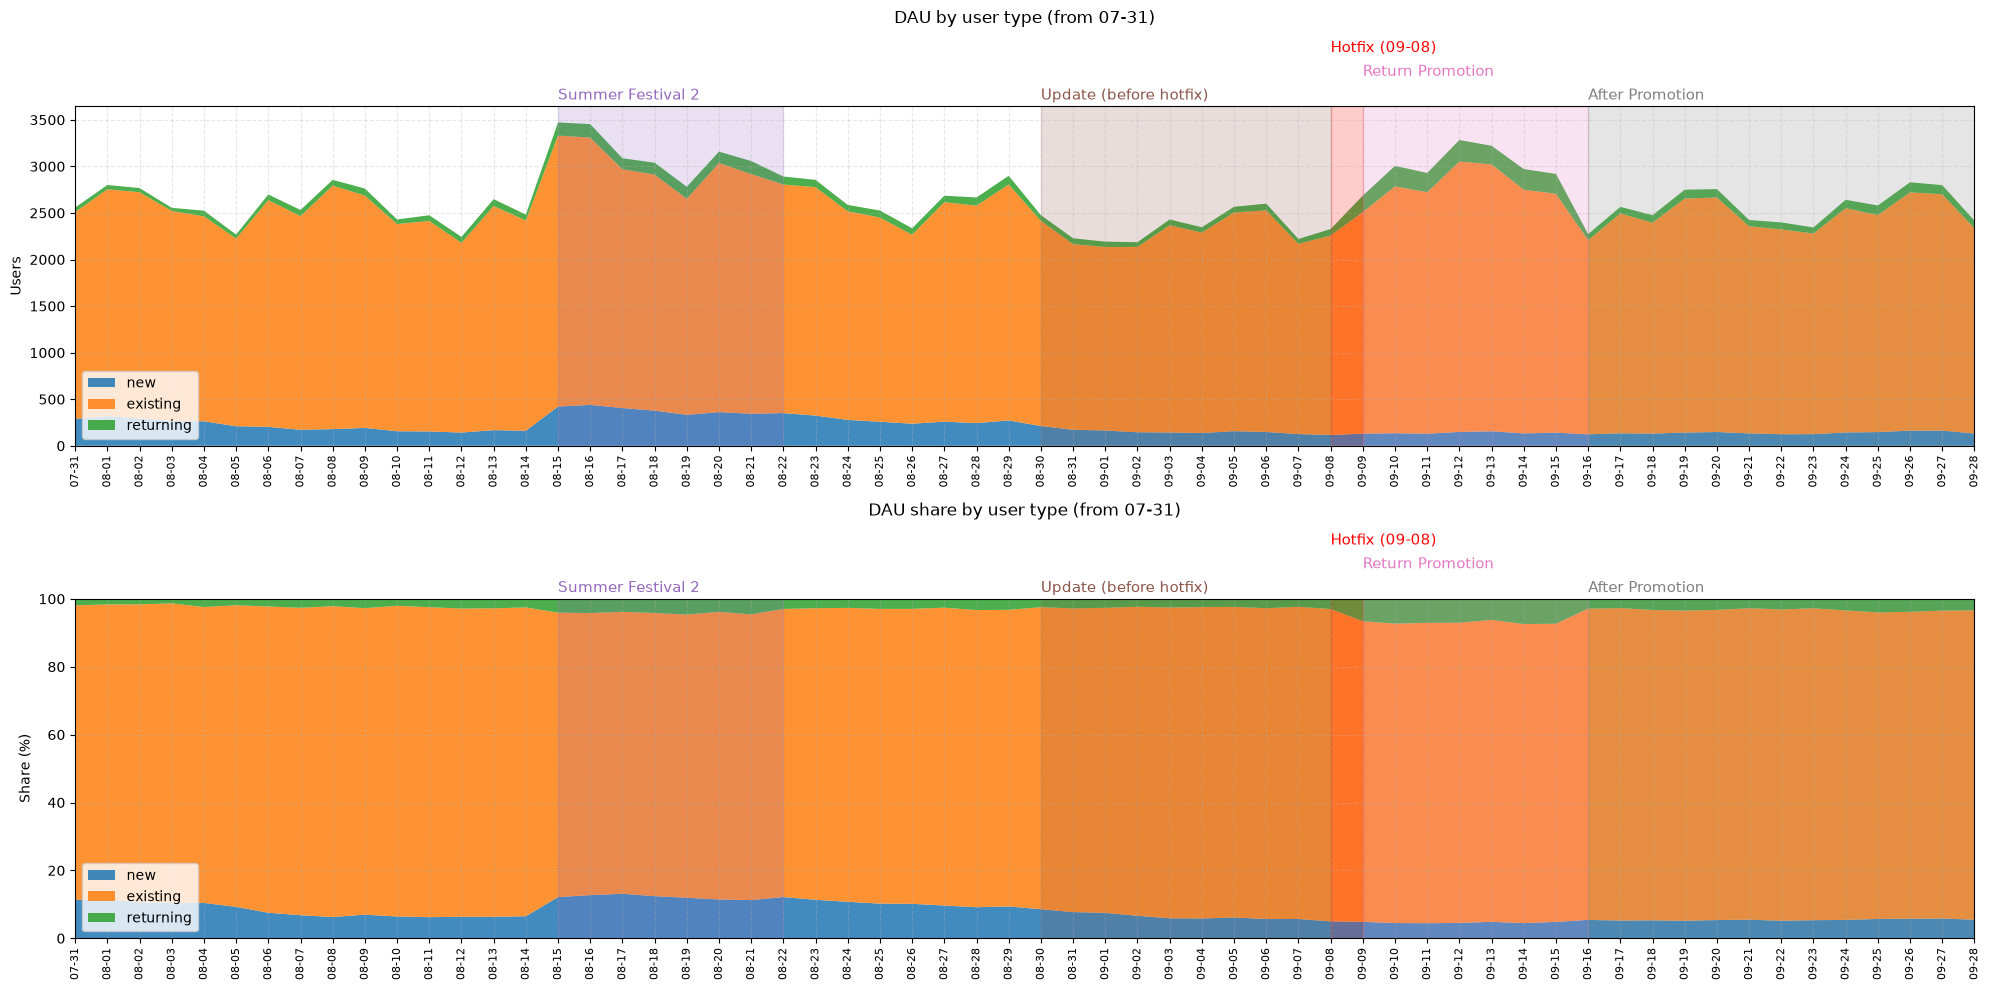

In [7]:
# 시각화: 유형별 DAU 누적 그래프 (위: 실제 유저 수, 아래: 비중 100%)

# 날짜별 유형 비중(%)
dau_type_total = dau_type.sum(axis=1)
dau_type_share = dau_type.div(dau_type_total, axis=0) * 100

# (데이터, 그래프 제목, y축 이름)
charts = [
    (dau_type, "DAU by user type (from 07-31)", "Users"),
    (dau_type_share, "DAU share by user type (from 07-31)", "Share (%)"),
]

# 프로모션·업데이트 기간: (기간 이름, 그래프 표시 이름, 음영 색, 글자 높이)
# 음영 색은 누적 그래프 색(파랑, 주황, 초록)과 겹치지 않게 고름
# 붙어 있는 기간은 글자 높이를 다르게 해서 이름이 겹치지 않게 함
period_styles = [
    ("여름 축제 2부", "Summer Festival 2", "tab:purple", 1.02),
    ("성장 개편 업데이트 이후 핫픽스 전", "Update (before hotfix)", "tab:brown", 1.02),
    ("핫픽스일", "Hotfix (09-08)", "red", 1.16),
    ("복귀 지원 프로모션", "Return Promotion", "tab:pink", 1.09),
    ("복귀 지원 프로모션 종료 후", "After Promotion", "tab:gray", 1.02),
]

fig, axes = plt.subplots(2, 1, figsize=(20, 10))

for ax, (data, title, ylabel) in zip(axes, charts):
    ax.stackplot(data.index, data["new"], data["existing"], data["returning"], labels=type_cols, alpha=0.85)
    ax.set_title(title, pad=60)      # 그래프 위쪽 기간 이름과 겹치지 않게 간격을 둠
    ax.set_ylabel(ylabel)
    ax.set_xlim(data.index.min(), data.index.max())
    ax.legend(loc="lower left")
    ax.grid(alpha=0.3, linestyle="--")

    # 기간 음영과 그래프 위쪽 이름
    for name, label, color, y_text in period_styles:
        start, end = periods[name]
        start_date = pd.Timestamp(start)
        end_date = pd.Timestamp(end) + pd.Timedelta(days=1)
        ax.axvspan(start_date, end_date, color=color, alpha=0.2)
        ax.text(start_date, y_text, label, transform=ax.get_xaxis_transform(), fontsize=11, color=color)

    # x축: 일자별 눈금, 90도 회전
    ax.set_xticks(data.index)
    ax.set_xticklabels(data.index.strftime("%m-%d"), rotation=90, fontsize=8)

axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

### 2-2. 프로모션별 유저 유형 변화 (평시 대비)
- 프로모션 기간의 유저 유형별 일평균 DAU와 평시 대비 증감률을 확인함

    - ① 신규 vs 기존·복귀: 세 프로모션 비교 (평시 기준: 전체 기간)
    - ② 신규, 기존, 복귀: 여름 축제 2부, 복귀 지원 프로모션 비교 (평시 기준: 7/31 이후)
    
- 여름 축제 1부는 복귀 유저를 구분할 수 없어 ①로만 확인함

In [8]:
# 프로모션별 유저 유형 일평균 DAU와 평시 대비 증감률

# 기간별 일평균과 평시 대비 증감률(%)을 만드는 함수
def summarize_by_period(df_by_date, rows):
    labels = date_period.reindex(df_by_date.index)
    period_mean = df_by_date.groupby(labels).mean().reindex(rows)
    change = (period_mean / period_mean.loc["평시"] - 1) * 100
    table = period_mean.join(change, rsuffix=" 평시 대비(%)")
    return table


# 값은 쉼표, 증감률은 부호를 붙여 표시하는 형식
def make_fmt(table):
    fmt = {}
    for col in table.columns:
        if col.endswith("평시 대비(%)"):
            fmt[col] = "{:+.1f}%"
        else:
            fmt[col] = "{:,.0f}"
    return fmt


# ① 신규 vs 기존·복귀: 평시 + 세 프로모션
group_rows = ["평시", "여름 축제 1부", "여름 축제 2부", "복귀 지원 프로모션"]
group_table = summarize_by_period(dau_group, group_rows)
print("\n[① 신규 vs 기존·복귀]")
display(group_table.style.format(make_fmt(group_table)))

# ② 신규, 기존, 복귀: 평시(7/31 이후) + 여름 축제 2부, 복귀 지원 프로모션
type_rows = ["평시", "여름 축제 2부", "복귀 지원 프로모션"]
type_table = summarize_by_period(dau_type, type_rows)
print("\n[② 신규, 기존, 복귀]")
display(type_table.style.format(make_fmt(type_table)))


[① 신규 vs 기존·복귀]


user_group,new,existing+returning,new 평시 대비(%),existing+returning 평시 대비(%)
평시,220,"2,301",+0.0%,+0.0%
여름 축제 1부,408,"2,900",+85.2%,+26.1%
여름 축제 2부,383,"2,767",+73.7%,+20.3%
복귀 지원 프로모션,139,"2,863",-36.8%,+24.4%



[② 신규, 기존, 복귀]


user_type,new,existing,returning,new 평시 대비(%),existing 평시 대비(%),returning 평시 대비(%)
평시,234,"2,311",65,+0.0%,+0.0%,+0.0%
여름 축제 2부,383,"2,635",132,+63.2%,+14.0%,+103.6%
복귀 지원 프로모션,139,"2,653",210,-40.6%,+14.8%,+225.0%


### 2-3. 통계적 가설 검정 1: 평시 vs 프로모션 차이 유의성 검증
- **목적**: 각 프로모션 기간의 유저 유형별 DAU가 평시와 차이가 있는지 확인하고자 함

| 검정 | 비교 | 평시 기준 |
|---|---|---|
| ① 신규, 기존·복귀 | 평시 vs 세 프로모션 각각 (여름 축제 1부, 2부, 복귀 지원 프로모션) | 전체 기간 |
| ② 기존, 복귀 | 평시 vs 여름 축제 2부, 복귀 지원 프로모션 각각 | 7/31 이후 |

- **방법**
    - 평시 일별 DAU와 프로모션 기간 일별 DAU를 Mann-Whitney U 검정(양측)으로 비교함
    - 한 유형마다 프로모션 수만큼 평시와 비교하므로 Bonferroni 보정을 적용함 (① p-value × 3, ② p-value × 2)
    - 증가인지 감소인지는 평시 대비(%) 부호로 판단함

- **유의수준**: α = 0.05

- **가설**
    - H0(귀무가설): 프로모션 기간의 일별 DAU는 평시와 **차이가 없다**
    - H1(대립가설): 프로모션 기간의 일별 DAU는 평시와 **차이가 있다**

In [9]:
# 평시 대비 검정에 쓸 함수
promo_periods = ["여름 축제 1부", "여름 축제 2부", "복귀 지원 프로모션"]


# 평시 vs 각 프로모션: Mann-Whitney U 검정 (Bonferroni 보정: p-value × 비교 프로모션 수)
# 평시는 입력 데이터에 있는 날짜 중 평시 (유형별 DAU는 7/31 이후 평시)
def compare_to_base(df_by_date, target_periods):
    labels = date_period.reindex(df_by_date.index)
    n_tests = len(target_periods)

    rows = []
    for col in df_by_date.columns:
        base_values = df_by_date.loc[labels == "평시", col]
        base_mean = base_values.mean()

        for name in target_periods:
            promo_values = df_by_date.loc[labels == name, col]
            promo_mean = promo_values.mean()
            change = (promo_mean / base_mean - 1) * 100
            p_raw = mannwhitneyu(promo_values, base_values, alternative="two-sided").pvalue
            p_adjusted = min(p_raw * n_tests, 1.0)

            rows.append({"지표": col, "프로모션": name,
                         "평시 일평균": base_mean, "프로모션 일평균": promo_mean, "평시 대비(%)": change,
                         "p-value": p_adjusted, "유의(p<0.05)": p_adjusted < 0.05})

    result = pd.DataFrame(rows).set_index(["지표", "프로모션"])
    return result


# 표시 형식
base_fmt = {"평시 일평균": "{:,.0f}", "프로모션 일평균": "{:,.0f}", "평시 대비(%)": "{:+.1f}%", "p-value": "{:.4f}"}


# ① 신규, 기존·복귀: 평시(전체 기간) vs 세 프로모션
group_base_test = compare_to_base(dau_group, promo_periods)
print("\n[① 신규, 기존·복귀]")
display(group_base_test.style.format(base_fmt))


[① 신규, 기존·복귀]


In [10]:
# ② 기존, 복귀: 평시(7/31 이후) vs 여름 축제 2부, 복귀 지원 프로모션
type_base_test = compare_to_base(dau_type[["existing", "returning"]], ["여름 축제 2부", "복귀 지원 프로모션"])
print("\n[② 기존, 복귀]")
display(type_base_test.style.format(base_fmt))


[② 기존, 복귀]


**결과 해석**
- True는 p-value < 0.05로 평시와의 차이가 유의함, False는 유의하지 않음을 뜻함 (모든 줄은 Bonferroni 보정 후 p-value 기준)

**요약**
- 신규 유저, 기존·복귀 유저(①)와 기존 유저, 복귀 유저(②): 모든 프로모션에서 p-value 0.05 미만으로, 평시와 비교하여 차이가 유의함
- 신규 유저는 복귀 지원 프로모션에서 감소(전체 기간 평시 대비 -36.8%)했고, 여름 축제 1부·2부에서는 증가함. 기존·복귀 유저, 기존 유저, 복귀 유저는 모든 프로모션에서 평시 대비 증가함

### 2-4. 통계적 가설 검정 2: 유저 유형 변화 차이 유의성 검증
- **목적**: 프로모션별 유저 유형의 평시 대비 증감률에 차이가 있는지 확인하고자 함

| 검정 | 비교 | 평시 기준 |
|---|---|---|
| ① 신규, 기존·복귀 | 세 프로모션 (여름 축제 1부, 2부, 복귀 지원 프로모션) | 전체 기간 |
| ② 기존, 복귀 | 여름 축제 2부 vs 복귀 지원 프로모션 | 7/31 이후 |

- **방법**

    - 일별 값을 평시 일평균 대비 증감률로 바꾼 뒤 프로모션끼리 비교함
    - 세 프로모션은 Kruskal-Wallis 검정 후 두 프로모션씩 Mann-Whitney U 검정(양측)으로 비교하고, 3쌍을 비교하므로 Bonferroni 보정(p-value × 3)을 적용함
    - 두 프로모션만 비교할 때는 Mann-Whitney U 검정만 사용함 (보정 없음)
    - 프로모션 기간이 각 7일로 표본이 작아 정규분포 여부를 확인하기 어렵고 튀는 값이 있어, 순위로 비교하는 비모수 검정을 사용함

- **유의수준**: α = 0.05

- **가설**
    - **1단계: 세 프로모션 전체 (Kruskal-Wallis)**
        - H0(귀무가설): 세 프로모션의 평시 대비 증감률은 서로 **차이가 없다**
        - H1(대립가설): 적어도 한 프로모션의 평시 대비 증감률이 다른 프로모션과 **차이가 있다**
        
    - **2단계: 두 프로모션씩 (Mann-Whitney U)**
        - H0(귀무가설): 두 프로모션의 평시 대비 증감률은 **차이가 없다**
        - H1(대립가설): 두 프로모션의 평시 대비 증감률은 **차이가 있다**

In [11]:
# 프로모션 간 비교에 쓸 함수

# 일별 값 → 일별 평시 대비 증감률(%) = 그날 값 / 평시 일평균 - 1
# 평시는 입력 데이터에 있는 날짜 중 평시 (유형별 DAU는 7/31 이후 평시)
def to_daily_change(df_by_date):
    labels = date_period.reindex(df_by_date.index)
    base_mean = df_by_date[labels == "평시"].mean()
    return (df_by_date / base_mean - 1) * 100


# 프로모션 간 평시 대비 증감률 비교
# - 세 프로모션: Kruskal-Wallis 검정 후, 두 프로모션씩 Mann-Whitney U 검정 (Bonferroni 보정: p-value × 비교 쌍 수)
# - 두 프로모션: Mann-Whitney U 검정 (비교가 1쌍이라 보정 없음)
def compare_promos(change_by_date, target_periods):
    labels = date_period.reindex(change_by_date.index)
    pairs = list(combinations(target_periods, 2))
    n_pairs = len(pairs)

    rows = []
    for col in change_by_date.columns:
        promo_values = {name: change_by_date.loc[labels == name, col] for name in target_periods}

        # 세 프로모션 전체 비교
        if len(target_periods) >= 3:
            p_all = kruskal(*promo_values.values()).pvalue
            rows.append({"지표": col, "비교": "세 프로모션 전체",
                         "전자 증감률(%)": None, "후자 증감률(%)": None, "차이(%p)": None,
                         "p-value": p_all, "유의(p<0.05)": p_all < 0.05})

        # 두 프로모션씩 비교
        for name_a, name_b in pairs:
            change_a = promo_values[name_a].mean()
            change_b = promo_values[name_b].mean()
            p_pair = mannwhitneyu(promo_values[name_a], promo_values[name_b], alternative="two-sided").pvalue
            p_adjusted = min(p_pair * n_pairs, 1.0)

            rows.append({"지표": col, "비교": f"{name_a} vs {name_b}",
                         "전자 증감률(%)": change_a, "후자 증감률(%)": change_b, "차이(%p)": change_a - change_b,
                         "p-value": p_adjusted, "유의(p<0.05)": p_adjusted < 0.05})

    result = pd.DataFrame(rows).set_index(["지표", "비교"])
    return result


# 표시 형식
compare_fmt = {"전자 증감률(%)": "{:+.1f}%", "후자 증감률(%)": "{:+.1f}%", "차이(%p)": "{:+.1f}%p", "p-value": "{:.4f}"}


# ① 신규, 기존·복귀: 세 프로모션 비교 (평시는 전체 기간 기준)
group_daily_change = to_daily_change(dau_group)
group_compare = compare_promos(group_daily_change, promo_periods)
print("\n[① 신규, 기존·복귀]")
display(group_compare.style.format(compare_fmt, na_rep=""))


[① 신규, 기존·복귀]


**결과 해석: ① 신규, 기존·복귀**
- True는 p-value < 0.05로 차이가 유의함, False는 유의하지 않음을 뜻함 (두 프로모션씩 비교한 줄은 Bonferroni 보정 후 p-value 기준)

- 1단계는 세 프로모션 전체 줄(Kruskal-Wallis), 2단계는 아래 세 줄(사후 검정, Mann-Whitney)로 확인함


**신규 유저**
- 1단계: p-value = 0.0010, True → 세 프로모션의 신규 유저 증감률에 차이가 있는 것으로 보임

- 2단계 (어느 프로모션이 다른가)
    - 축제 1부 vs 축제 2부: +85.2% vs +73.7%, False → 두 축제는 비슷함
    - 축제 1부 vs 복귀 지원: +85.2% vs -36.8%, True → 차이가 유의함
    - 축제 2부 vs 복귀 지원: +73.7% vs -36.8%, True → 차이가 유의함

- → **두 축제는 비슷**하고, 복귀 지원 프로모션만 신규 유저 증감률이 낮은 것으로 보임


**기존·복귀 유저**
- 1단계: p-value = 0.3631, False → 세 프로모션 간 차이가 있다고 보기 어려움

- 2단계: 모두 False이고, 증감률도 +20.3%~+26.1%로 비슷함 → 1단계와 같은 결론

- → **세 프로모션 모두 기존·복귀 유저를 비슷하게 증가**시킨 것으로 보임

**요약**
- 신규 유저: 축제 1부와 2부의 신규 유저 증감률의 차이는 유의하지 않음(p-value = 0.9185)  
  (전체 기간 평시 대비 축제 1부 +85.2%, 2부 +73.7%, 복귀 지원 -36.8%)

- 기존·복귀 유저: 세 프로모션 모두 전체 기간 평시 대비 +20~26% 증가했고, 프로모션 간 차이는 유의하지 않음(p-value = 0.3631).  
  세 프로모션이 기존·복귀 유저에 비슷한 효과를 낸 것으로 보임

In [12]:
# ② 기존, 복귀: 여름 축제 2부 vs 복귀 지원 프로모션 (평시는 7/31 이후 기준)
type_daily_change = to_daily_change(dau_type[["existing", "returning"]])
type_compare = compare_promos(type_daily_change, ["여름 축제 2부", "복귀 지원 프로모션"])
print("\n[② 기존, 복귀]")
display(type_compare.style.format(compare_fmt, na_rep=""))


[② 기존, 복귀]


,,전자 증감률(%),후자 증감률(%),차이(%p),p-value,유의(p<0.05)
지표,비교,,,,,
existing,여름 축제 2부 vs 복귀 지원 프로모션,+14.0%,+14.8%,-0.8%p,0.8478,False
returning,여름 축제 2부 vs 복귀 지원 프로모션,+103.6%,+225.0%,-121.4%p,0.0006,True


**결과 해석: ② 기존, 복귀**
- 두 프로모션만 비교해 Mann-Whitney 검정 1번으로 확인함 (보정 없음)

**기존 유저**
- 축제 2부 vs 복귀 지원: +14.0% vs +14.8%, 차이 -0.8%p  
  p-value = 0.8478, False → 두 프로모션은 비슷함

**복귀 유저**
- 축제 2부 vs 복귀 지원: +103.6% vs +225.0%, 차이 -121.4%p  
  p-value = 0.0006, True → 차이가 유의함

**요약**
- 기존 유저: 7/31 이후 평시 대비 두 프로모션 모두 약 +14% 수준 증가했고, 차이가 미미하며 유의하지 않음(p-value = 0.8478)

- 복귀 유저: 7/31 이후 평시 대비 축제 2부 +103.6%, 복귀 지원 +225.0%로 복귀 지원 프로모션의 증가 폭이 유의하게 큼(p-value = 0.0006).  
  복귀 지원 프로모션이 복귀 유저 유입에 효과가 있었던 것으로 보임

### **요점**
- 여름 축제 1부·2부의 신규 유저 증가 폭의 차이는 유의하지 않음 (전체 기간 평시 대비 +85.2%, +73.7%)
- 여름 축제 1부·2부와 복귀 지원 프로모션의 기존·복귀 유저 증가 폭의 차이는 유의하지 않음 (전체 기간 평시 대비 +20~26%)

- 마케팅 광고가 포함된 프로모션에서 신규 유저 유입이 많아, **신규 유저는 마케팅에 크게 반응하는 것으로 보임**
- 복귀 지원 프로모션은 마케팅을 하지 않았음에도 여름 축제 2부보다 복귀 유저가 더 많이 증가함 (7/31 이후 평시 대비 +225.0% vs +103.6%).  
  **복귀 지원 프로모션에서 사용한 방법(복귀 보상 등)이 복귀 유저를 끌어오는 데 효과적**이었던 것으로 보임

## 3. 프로모션 효과 분석 - 주요 지표 변화

### 3-1. 프로모션별 주요 지표 변화 (평시 대비)
- 프로모션 기간의 DAU, 매출, 결제 전환율, ARPPU 일평균과 평시 대비 증감률을 확인함 (평시는 전체 기간 기준)

In [13]:
# 프로모션별 주요 지표 일평균과 평시 대비 증감률: DAU, 매출, 결제 전환율, ARPPU

# 일별 DAU
dau = daily_clean.groupby("date")["user_id"].nunique()

# 일별 결제 유저 수, 매출 (결제가 없는 날은 0)
pay_date = payments_clean["paid_at"].dt.normalize()
payers = payments_clean.groupby(pay_date)["user_id"].nunique().reindex(all_dates, fill_value=0)
revenue = payments_clean.groupby(pay_date)["amount_krw"].sum().reindex(all_dates, fill_value=0)

# 결제 전환율(%), ARPPU
pay_conv = payers / dau * 100
arppu = revenue / payers

daily_metrics = pd.DataFrame({
    "DAU": dau,
    "revenue": revenue,
    "pay_conv(%)": pay_conv,
    "ARPPU": arppu,
})

metric_table = summarize_by_period(daily_metrics, group_rows)

# 결제 전환율만 소수점 둘째 자리까지 표시
metric_fmt = make_fmt(metric_table)
metric_fmt["pay_conv(%)"] = "{:.2f}"
display(metric_table.style.format(metric_fmt))

,DAU,revenue,pay_conv(%),ARPPU,DAU 평시 대비(%),revenue 평시 대비(%),pay_conv(%) 평시 대비(%),ARPPU 평시 대비(%)
평시,"2,521","1,050,643",1.03,"40,506",+0.0%,+0.0%,+0.0%,+0.0%
여름 축제 1부,"3,308","2,195,757",1.69,"39,257",+31.2%,+109.0%,+65.0%,-3.1%
여름 축제 2부,"3,150","1,912,743",1.48,"41,016",+24.9%,+82.1%,+44.7%,+1.3%
복귀 지원 프로모션,"3,002","1,394,014",1.12,"41,155",+19.1%,+32.7%,+9.5%,+1.6%


### 3-2. 프로모션 간 주요 지표 변화 비교 (통계적 가설 검정)
- **목적**: 세 프로모션의 DAU, 매출, 결제 전환율, ARPPU 평시 대비 증감률에 차이가 있는지 확인함 (평시는 전체 기간 기준)
- 방법, 유의수준, 가설은 2-4의 세 프로모션 비교와 동일

In [14]:
# 주요 지표 평시 대비 증감률 비교: 세 프로모션 (함수는 2-4에서 정의)
metric_daily_change = to_daily_change(daily_metrics)
metric_compare = compare_promos(metric_daily_change, promo_periods)
display(metric_compare.style.format(compare_fmt, na_rep=""))

### **요점**
- 매출은 여름 축제 1부·2부 간 증감률 차이는 유의하지 않았고, 두 축제와 복귀 지원 프로모션 간 차이는 유의함 (전체 기간 평시 대비)  
  - 여름 축제 1부 vs 복귀 지원: +109.0% vs +32.7%, 차이 +76.3%p  
  - 여름 축제 2부 vs 복귀 지원: +82.1% vs +32.7%, 차이 +49.4%p  
  - 복귀 지원 프로모션보다 **여름 축제 1부·2부가 매출 증가에 더 많이 기여**한 것으로 보임

- 결제 전환율 역시 여름 축제 1부·2부 간 증감률 차이는 유의하지 않았고, 두 축제와 복귀 지원 프로모션 간 차이는 유의함 (전체 기간 평시 대비)  
  - 여름 축제 1부 vs 복귀 지원: +65.0% vs +9.5%, 차이 +55.5%p  
  - 여름 축제 2부 vs 복귀 지원: +44.7% vs +9.5%, 차이 +35.2%p
  - 복귀 지원 프로모션보다 **여름 축제 1부·2부가 결제 전환율 증가에 더 많이 기여**한 것으로 보임

- 매출 및 결제 전환율 상승에 `프로모션 코인과 한정 코스튬 판매, 결제 상품 보너스`가 영향을 주었을 수 있으나,  
  주어진 데이터로는 해당 상품의 판매 내역을 확인할 수 없어 추후 확인이 필요함.

- **DAU**는 세 프로모션 전체로는 차이가 유의했으나(p-value = 0.0351), 두 프로모션씩 비교한 사후 검정에서는 유의한 쌍이 없음
- **ARPPU**는 프로모션 간 차이가 유의하지 않음

## 4. 성장 개편 업데이트 효과 분석
`01_EDA.ipynb`의 4장(DAU, WAU)에서 남긴 질문을 확인하기 위한 추가 분석

- **성장 개편 업데이트(8/30) 이후**: 핫픽스(9/8)까지 평시보다 낮은 DAU(평시 대비 -3.4%)가 이어졌음.  
  복귀 지원 프로모션 기간(9/9~9/15)에는 DAU가 평시 대비 +19.5%로 회복되었고, 이후에도 일 3,000명 전후로 유지됨.

  - 업데이트 이후 떨어졌던 DAU가 핫픽스로 필드 사냥 경험치 하향폭을 완화한 뒤 회복되어, 경험치 하향이 유저 접속 감소에 영향을 줬을 가능성이 있음.  
    다만 핫픽스 다음 날 복귀 지원 프로모션이 시작되어 DAU 회복에 두 요인이 함께 작용했을 수 있으므로, 핫픽스와 프로모션의 영향을 나누어 확인하고자 함.


**업데이트 내용**

- **성장 개편 업데이트 내용(8/30)**
  - ① 필드 사냥 경험치 20% 하향(성장 속도 조정)
  - ② Lv45 이상 신규 지역 추가
  - ③ 장비 강화 패키지 판매 시작
  - ④ 대용량 클라이언트 패치(모바일은 업데이트 완료까지 시간이 걸림)

- **핫픽스 내용(9/8)**
  - 필드 경험치 하향폭을 20% → 10%로 완화 (09-08부터 적용)

- **복귀 지원 프로모션 내용(9/9 ~ 9/15)**
  - 일정 기간 접속하지 않은 유저 대상 **복귀 보상**과 **일반 유저 대상 출석 보상**

### **가설 설정**
DAU 회복의 원인을 나누어 보기 위해, 복귀 지원 프로모션 기간(9/9 ~ 9/15)과 프로모션 종료 후(9/16 ~ 9/28)를 나누어 확인함. 

복귀 지원 프로모션에는 일반 유저 대상 출석 보상도 포함되어 있어, 프로모션 기간에 기존 유저가 늘어난 것도 보상의 영향일 수 있음.  
따라서 프로모션 종료 후에도 기존 유저가 핫픽스 전(8/30~9/7)보다 높게 유지되는지를 함께 확인함.  

핫픽스의 영향 판단을 위해 아래 두 기간의 기존 유저 수를 비교함.
- 성장 개편 업데이트 이후 핫픽스 전(8/30 ~ 9/7)
- 프로모션 종료 후(9/16 ~ 9/28)

**결과 판단**
* 기존 유저 수 증가 → 핫픽스(경험치 하향폭 완화)의 효과로 판단
* 기존 유저 수 유지·감소 → 핫픽스의 효과는 적었고, 프로모션의 영향이 있었을 것으로 판단

### 4-1. 핫픽스 전후 기존 유저 DAU 비교

In [15]:
# 기간별 기존 유저 일평균 DAU와 평시 대비, 핫픽스 전 대비 증감률 (평시는 7/31 이후 기준)
hotfix_rows = ["평시", "성장 개편 업데이트 이후 핫픽스 전", "복귀 지원 프로모션", "복귀 지원 프로모션 종료 후"]
existing_table = summarize_by_period(dau_type[["existing"]], hotfix_rows)

# 핫픽스 전 대비 증감률(%)
before_hotfix_mean = existing_table.loc["성장 개편 업데이트 이후 핫픽스 전", "existing"]
existing_table["핫픽스 전 대비(%)"] = (existing_table["existing"] / before_hotfix_mean - 1) * 100

existing_fmt = make_fmt(existing_table)
existing_fmt["핫픽스 전 대비(%)"] = "{:+.1f}%"
display(existing_table.style.format(existing_fmt))

user_type,existing,existing 평시 대비(%),핫픽스 전 대비(%)
평시,"2,311",+0.0%,+7.8%
성장 개편 업데이트 이후 핫픽스 전,"2,145",-7.2%,+0.0%
복귀 지원 프로모션,"2,653",+14.8%,+23.7%
복귀 지원 프로모션 종료 후,"2,335",+1.0%,+8.9%


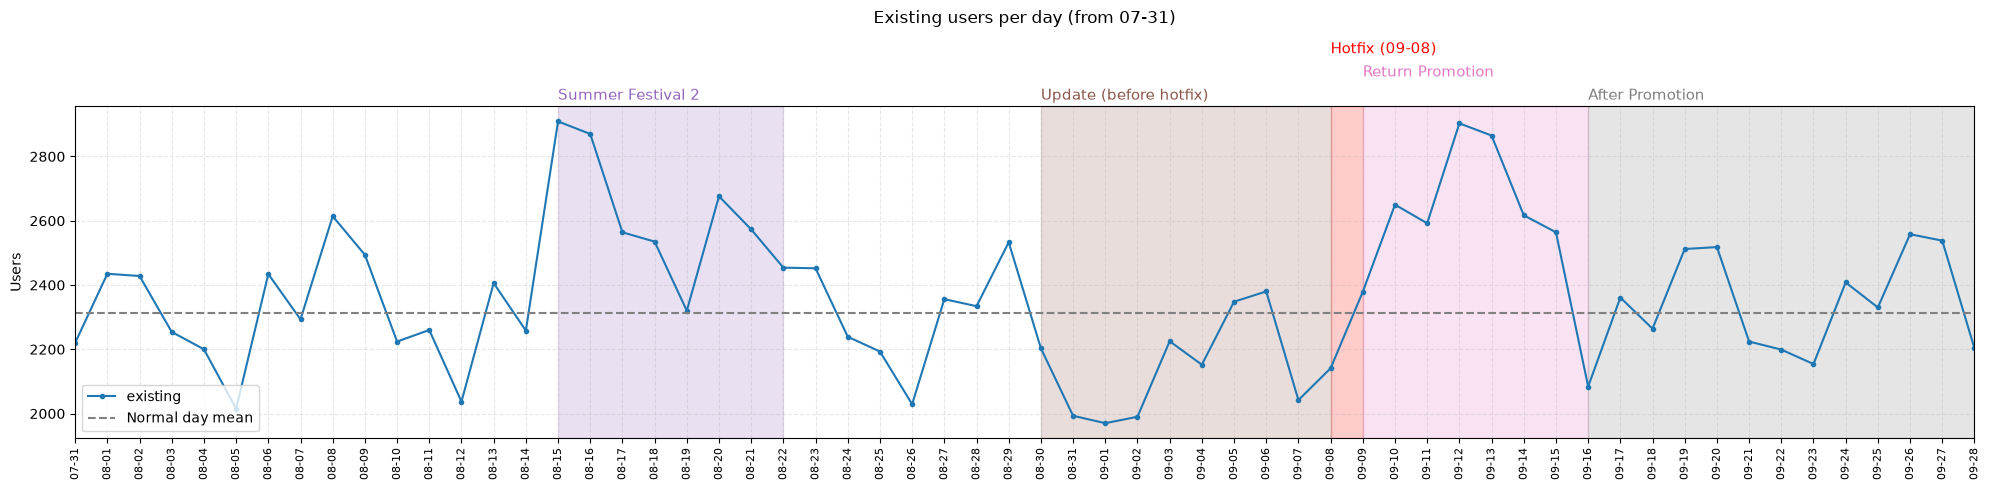

In [16]:
# 시각화: 일별 기존 유저 DAU (7/31 이후, 기간 음영은 2-1과 동일)
existing_daily = dau_type["existing"]
base_existing_mean = existing_table.loc["평시", "existing"]

fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(existing_daily.index, existing_daily, marker="o", markersize=3, label="existing")
ax.axhline(base_existing_mean, color="gray", linestyle="--", label="Normal day mean")
ax.set_title("Existing users per day (from 07-31)", pad=60)
ax.set_ylabel("Users")
ax.set_xlim(existing_daily.index.min(), existing_daily.index.max())
ax.legend(loc="lower left")
ax.grid(alpha=0.3, linestyle="--")

# 기간 음영과 그래프 위쪽 이름
for name, label, color, y_text in period_styles:
    start, end = periods[name]
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end) + pd.Timedelta(days=1)
    ax.axvspan(start_date, end_date, color=color, alpha=0.2)
    ax.text(start_date, y_text, label, transform=ax.get_xaxis_transform(), fontsize=11, color=color)

# x축: 일자별 눈금, 90도 회전
ax.set_xticks(existing_daily.index)
ax.set_xticklabels(existing_daily.index.strftime("%m-%d"), rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

### 4-2. 통계적 가설 검정: 핫픽스 전 vs 프로모션 종료 후
- H0(귀무가설): 프로모션 종료 후(9/16~9/28) 기존 유저 일평균 수는 핫픽스 전(8/30~9/7)과 차이가 없다
- H1(대립가설): 프로모션 종료 후 기존 유저 일평균 수는 핫픽스 전과 차이가 있다

In [17]:
# 핫픽스 전 vs 복귀 지원 프로모션 종료 후: 일별 기존 유저 수 비교 (Mann-Whitney U, 양측, 비교 1번이라 보정 없음)
labels = date_period.reindex(dau_type.index)
before_values = dau_type.loc[labels == "성장 개편 업데이트 이후 핫픽스 전", "existing"]
after_values = dau_type.loc[labels == "복귀 지원 프로모션 종료 후", "existing"]

before_mean = before_values.mean()
after_mean = after_values.mean()
change = (after_mean / before_mean - 1) * 100
p_value = mannwhitneyu(before_values, after_values, alternative="two-sided").pvalue

hotfix_test = pd.DataFrame({
    "핫픽스 전 일평균": [before_mean],
    "종료 후 일평균": [after_mean],
    "핫픽스 전 대비(%)": [change],
    "p-value": [p_value],
    "유의(p<0.05)": [p_value < 0.05],
}, index=["핫픽스 전 vs 복귀 지원 프로모션 종료 후"])

hotfix_fmt = {"핫픽스 전 일평균": "{:,.0f}", "종료 후 일평균": "{:,.0f}", "핫픽스 전 대비(%)": "{:+.1f}%", "p-value": "{:.4f}"}
display(hotfix_test.style.format(hotfix_fmt))

,핫픽스 전 일평균,종료 후 일평균,핫픽스 전 대비(%),p-value,유의(p<0.05)
종료 후 vs 핫픽스 전,"2,145","2,335",+8.9%,0.0252,True


- 핫픽스 전 vs 복귀 지원 프로모션 종료 후 기존 유저 일평균 DAU 차이가 유의해(p-value = 0.0252), 귀무가설을 기각함.  
  프로모션 종료 후 기존 유저 일평균 DAU가 핫픽스 전보다 증가해, 경험치 하향폭 완화가 효과가 있었던 것으로 판단됨

- 또한 복귀 지원 프로모션 종료 후 기존 유저 DAU가 평시 수준으로 회복되어(7/31 이후 평시 대비 +1.0%), 유저들이 경험치 하향에 민감하게 반응한 것으로 보임

## 요약

### 유저 유형 변화
- 세 프로모션 모두 평시보다 기존·복귀 유저가 증가했고, 프로모션 간 차이는 크지 않았음
- 신규 유저는 마케팅 광고가 포함된 여름 축제 1부·2부에서 크게 증가해, 신규 유저는 마케팅에 크게 반응하는 것으로 보임
- 복귀 유저는 마케팅 없이 진행한 복귀 지원 프로모션에서 여름 축제 2부보다 더 많이 증가해, 복귀 보상이 복귀 유저를 끌어오는 데 효과적이었던 것으로 보임

### 주요 지표 변화
- 매출과 결제 전환율은 여름 축제 1부·2부가 복귀 지원 프로모션보다 크게 증가해, 축제 또는 축제 기간 판매한 상품이 매출 증가에 기여한 것으로 추측됨
  - **한계점**: 축제 기간 판매한 한정 코스튬 판매 상품 데이터가 없어, 어떤 상품이 매출 증가에 기여했는지 확인할 수 없음. 추후 확인 필요
- ARPPU는 프로모션 간 차이가 거의 없어, 매출 증가는 1명당 결제액보다 결제하는 유저 수 증가의 영향이 큰 것으로 판단됨

### 성장 개편 업데이트와 핫픽스
- 복귀 지원 프로모션 종료 후에도 평균 기존 유저 DAU가 핫픽스 전보다 높아, 경험치 하향폭 완화(핫픽스)가 효과가 있었던 것으로 보임
- 핫픽스 이후 기존 유저가 평시 수준으로 회복되어, 유저들이 경험치 하향에 민감하게 반응한 것으로 보임